# Interpretabilidad (Etapa B) - scaffolding

La consigna de TP3 (Etapa B) pide dos cosas sobre los modelos de la Etapa A:

1. Usar SHAP y/o Feature Importance para identificar qué variables más afectan al error.
2. Analizar si el sesgo detectado antes (notebooks 2 y 4: ciclo diario, bioma, elevación) fue **efectivamente
   capturado y corregido** por el modelo refinado.

Esta notebook arma el *scaffolding*: el pipeline completo (carga de features, importancia, SHAP, comparación de
sesgo pre/post corrección) construido y **probado de punta a punta con dos modelos placeholder** (una regresión
lineal y un Random Forest, ambos sin tunear) entrenados sobre el dataset de features de la sección "Error de
pronóstico" de `3_analisis_temporal.ipynb`.
Los placeholder no son el entregable de Etapa A -son sólo para validar que el scaffolding corre- y se reemplazan por
los modelos reales en cuanto estén listos (sección 6 deja la lista exacta de qué reemplazar).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo

PROCESSED = '../data/processed/'
OUT = '../data/out/interpretabilidad/'

aplicar_estilo()
figuras = {}

C:\Users\usuario\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga: features (`3_analisis_temporal.ipynb`) + target y variables de sesgo (`dataset_modelado.csv`)

El dataset de features de la sección "Error de pronóstico" de `3_analisis_temporal.ipynb` (`panel_features_error_temp_c.csv`)
trae los predictores -lags 6/24/48, rolling, dirección de viento, vecinas-, pero no el target ni las variables de
corte para el análisis de sesgo (`hora_local`, `bioma`, `elevation`) -esas están en `dataset_modelado.csv`. Se
mergea por `station_id` + `target_hour_utc`.

In [2]:
features = pd.read_csv(PROCESSED + 'panel_features_error_temp_c.csv', parse_dates=['target_hour_utc'])

cols_modelado = ['station_id', 'target_hour_utc', 'error_temp_c', 'abs_error_temp_c', 'target_valido_temp_c',
                  'hora_local', 'bioma', 'elevation', 'split']
modelado = pd.read_csv(PROCESSED + 'dataset_modelado.csv', usecols=cols_modelado, parse_dates=['target_hour_utc'])

# features también trae su propia columna error_temp_c (la versión con interpolación acotada de 3_analisis_temporal.ipynb,
# pensada para el diagnóstico de estacionariedad/ACF, no como target): se dropea antes del merge para que no haya
# ambigüedad de nombres -el target real es siempre el de dataset_modelado.csv (el "crudo", fcst - obs).
features = features.drop(columns='error_temp_c')

assert not features.duplicated(['station_id', 'target_hour_utc']).any(), 'panel_features_error_temp_c tiene pares estación+hora repetidos'
assert not modelado.duplicated(['station_id', 'target_hour_utc']).any(), 'dataset_modelado tiene pares estación+hora repetidos'

datos = features.merge(modelado, on=['station_id', 'target_hour_utc'])
print(f'{len(datos):,} filas tras el merge')

165,184 filas tras el merge


## 2. Matriz de features (X) y target (y)

Sólo filas con target válido y sin ningún faltante en las features -mismo criterio de `6_baselines_globales.ipynb`
(`mascara_eval`), pero sobre el set de features del error de `3_analisis_temporal.ipynb` en vez de sólo los 4 lags
de los baselines.

In [3]:
EXCLUIR = {'station_id', 'target_hour_utc'}
FEATURES = [c for c in features.columns if c not in EXCLUIR and not c.endswith('_imputado')]

mascara = datos['target_valido_temp_c'] & datos[FEATURES].notna().all(axis=1)
datos_modelo = datos[mascara].copy()

print(f'{len(datos_modelo):,} de {len(datos):,} filas entran al modelo ({100 * mascara.mean():.1f}%)')
print(f'Features: {FEATURES}')

X_train = datos_modelo.loc[datos_modelo['split'] == 'train', FEATURES]
y_train = datos_modelo.loc[datos_modelo['split'] == 'train', 'error_temp_c']
X_test = datos_modelo.loc[datos_modelo['split'] == 'test', FEATURES]
y_test = datos_modelo.loc[datos_modelo['split'] == 'test', 'error_temp_c']

print(f'train: {len(X_train):,} filas | test: {len(X_test):,} filas')

97,507 de 165,184 filas entran al modelo (59.0%)
Features: ['error_temp_c_lag6', 'error_temp_c_lag24', 'error_temp_c_lag48', 'error_temp_c_roll3_mean', 'obs_wind_direction_sin_lag6', 'obs_wind_direction_cos_lag6', 'error_temp_c_vecinas_lag6_mean']
train: 70,120 filas | test: 27,387 filas


## 3. Modelos placeholder

**Esto NO es la Etapa A.** Son dos modelos mínimos, sin tuning ni validación cruzada, sólo para tener algo real sobre
lo que correr feature importance y SHAP y así dejar probado el resto del pipeline. Uno lineal (interpretable por
coeficientes) y uno de ensamble (para el que tiene sentido usar SHAP) -mismo esquema de dos modelos que pide la
consigna, para que la sección 5 pueda comparar ambos contra el baseline "no corregir" de `6_baselines_globales.ipynb`.

In [4]:
modelo_interpretable_placeholder = LinearRegression()
modelo_interpretable_placeholder.fit(X_train, y_train)

modelo_min_error_placeholder = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=0, n_jobs=-1)
modelo_min_error_placeholder.fit(X_train, y_train)

print('Modelos placeholder entrenados (regresión lineal + random forest)')

Modelos placeholder entrenados (regresión lineal + random forest)


In [5]:
def mae(y_true, y_pred):
    return np.abs(y_true - y_pred).mean()


resultados = pd.DataFrame({
    'modelo': ['cero (no corregir)', 'interpretable_placeholder (lineal)', 'min_error_placeholder (random forest)'],
    'MAE_test': [
        mae(y_test, 0),
        mae(y_test, modelo_interpretable_placeholder.predict(X_test)),
        mae(y_test, modelo_min_error_placeholder.predict(X_test)),
    ],
})
resultados['mejora_vs_cero_pct'] = 100 * (1 - resultados['MAE_test'] / resultados.loc[0, 'MAE_test'])
resultados.round(3)

,modelo,MAE_test,mejora_vs_cero_pct
0,cero (no corregir),1.240,0.000
1,interpretable_placeholder (lineal),1.143,7.797
2,min_error_placeholder (random forest),1.161,6.391


Esta tabla es sólo para confirmar que el pipeline de evaluación funciona -**no reemplaza la Evaluación real de
Etapa A**, que le corresponde a los modelos finales entrenados con validación cruzada.

## 4. Feature Importance (modelo interpretable)

Función genérica: usa `coef_` si el modelo es lineal, o `feature_importances_` si es de árbol/ensamble. Así sirve
para cualquiera de los dos modelos reales, sea cual sea el algoritmo que termine usando cada uno.

In [6]:
def importancia_features(modelo, nombres_features):
    if hasattr(modelo, 'coef_'):
        valores = np.abs(modelo.coef_)
        tipo = 'coeficiente (valor absoluto)'
    elif hasattr(modelo, 'feature_importances_'):
        valores = modelo.feature_importances_
        tipo = 'feature_importances_'
    else:
        raise AttributeError('El modelo no tiene coef_ ni feature_importances_: pasar otra técnica de importancia.')
    return pd.Series(valores, index=nombres_features, name=tipo).sort_values(ascending=False)


importancia_interpretable = importancia_features(modelo_interpretable_placeholder, FEATURES)
importancia_interpretable

error_temp_c_lag6                 0.337307
error_temp_c_lag24                0.308812
error_temp_c_lag48                0.219403
error_temp_c_roll3_mean           0.218753
obs_wind_direction_cos_lag6       0.046079
obs_wind_direction_sin_lag6       0.010596
error_temp_c_vecinas_lag6_mean    0.005047
Name: coeficiente (valor absoluto), dtype: float64

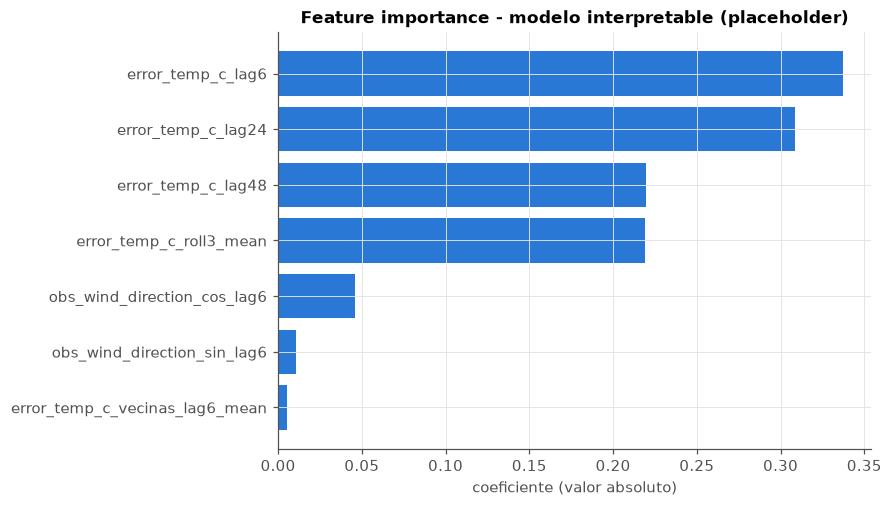

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.barh(importancia_interpretable.index[::-1], importancia_interpretable.values[::-1], color=AZUL)
ax.set(xlabel=importancia_interpretable.name, title='Feature importance - modelo interpretable (placeholder)')
figuras['01_feature_importance_interpretable'] = fig
plt.show()

## 5. SHAP (modelo de mínimo error)

`TreeExplainer` para el Random Forest -exacto y rápido para modelos de árbol-. Si el modelo real de Etapa A termina
siendo lineal, `importancia_features` (sección 4) ya alcanza y SHAP es redundante; si es otro tipo de ensamble
(XGBoost, LightGBM, GradientBoosting de sklearn) `TreeExplainer` también sirve sin cambios. Para un modelo sin
estructura de árbol ni lineal, `shap.KernelExplainer` es el fallback genérico (mucho más lento, usar sólo si hace
falta).

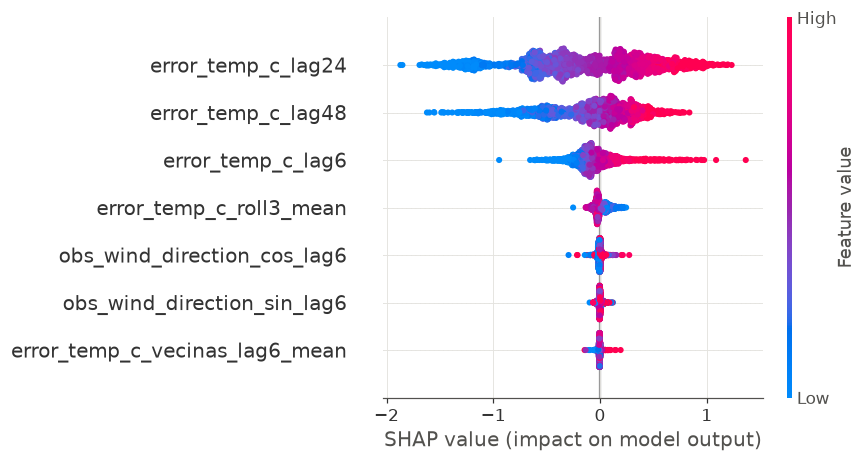

In [8]:
MUESTRA_SHAP = min(2000, len(X_test))
X_shap = X_test.sample(MUESTRA_SHAP, random_state=0) if len(X_test) > MUESTRA_SHAP else X_test

explainer = shap.TreeExplainer(modelo_min_error_placeholder)
shap_values = explainer(X_shap)

shap.summary_plot(shap_values, X_shap, show=False)
fig = plt.gcf()
figuras['02_shap_summary_min_error'] = fig
plt.show()

In [9]:
importancia_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES, name='|SHAP| promedio').sort_values(ascending=False)
importancia_shap

error_temp_c_lag24                0.499763
error_temp_c_lag48                0.313998
error_temp_c_lag6                 0.157763
error_temp_c_roll3_mean           0.047631
obs_wind_direction_cos_lag6       0.013585
obs_wind_direction_sin_lag6       0.012003
error_temp_c_vecinas_lag6_mean    0.007972
Name: |SHAP| promedio, dtype: float64

## 6. ¿El modelo capturó el sesgo ya detectado? (pre vs. post corrección)

Notebooks anteriores ya encontraron sesgo del pronóstico en dos cortes: **ciclo diario** (`2_relaciones-bivariadas.ipynb`,
`error_por_hora`) y **bioma** (`4_atributos_geograficos.ipynb`). La pregunta de esta sección -la que pide la consigna
explícitamente para Etapa B- es si ese sesgo sigue estando en el *residuo* del modelo (error observado menos
corrección predicha) o si el modelo lo absorbió.

Función genérica: agrupa por una columna de corte y compara el error absoluto medio **sin corregir**
(`abs_error_temp_c`, el pronóstico tal cual) contra el error absoluto medio **del residuo** de cada modelo
(`|error_temp_c - predicción|`) en ese mismo corte -si el modelo capturó el sesgo, la brecha entre categorías del
corte debería achicarse en el residuo respecto a la serie sin corregir.

In [10]:
def comparar_sesgo_por_corte(datos_split, columna_corte, predicciones, min_n=20):
    base = pd.DataFrame({
        columna_corte: datos_split[columna_corte].values,
        'sin_corregir': datos_split['abs_error_temp_c'].values,
    })
    for nombre, pred in predicciones.items():
        base[nombre] = np.abs(datos_split['error_temp_c'].values - pred)

    resumen = base.groupby(columna_corte).agg(['mean', 'count'])
    n_por_grupo = resumen[('sin_corregir', 'count')]
    resumen = resumen.loc[n_por_grupo >= min_n]
    return resumen.xs('mean', axis=1, level=1)


datos_test = datos_modelo[datos_modelo['split'] == 'test']
predicciones_test = {
    'interpretable_placeholder': modelo_interpretable_placeholder.predict(X_test),
    'min_error_placeholder': modelo_min_error_placeholder.predict(X_test),
}

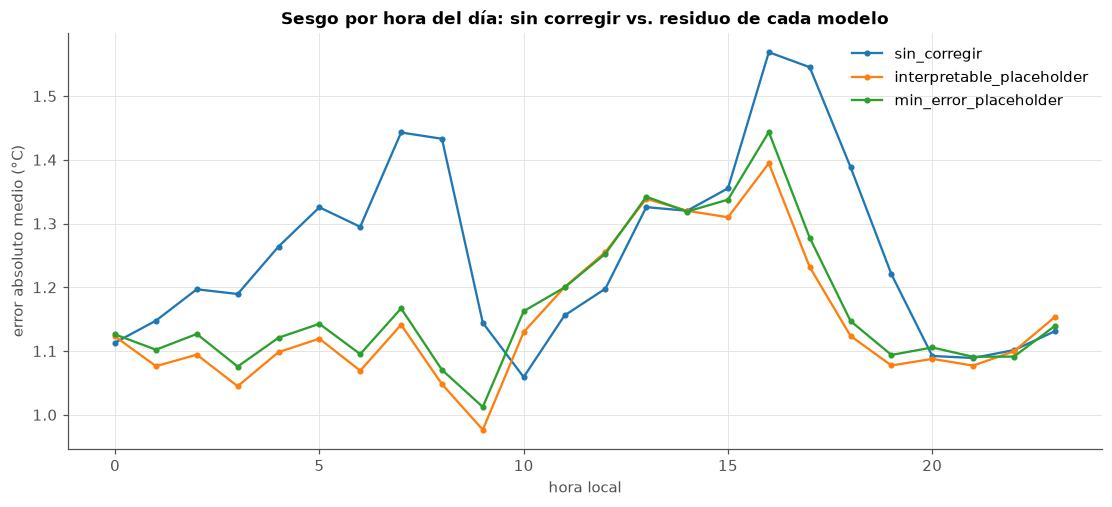

,sin_corregir,interpretable_placeholder,min_error_placeholder
hora_local,,,
0,1.113,1.123,1.126
1,1.148,1.076,1.102
2,1.197,1.094,1.127
3,1.189,1.045,1.076
4,1.264,1.098,1.121
5,1.325,1.119,1.143
6,1.295,1.069,1.095
7,1.443,1.141,1.167
8,1.433,1.048,1.070


In [11]:
sesgo_hora = comparar_sesgo_por_corte(datos_test, 'hora_local', predicciones_test)

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
sesgo_hora.plot(ax=ax, marker='o', ms=3)
ax.set(xlabel='hora local', ylabel='error absoluto medio (°C)', title='Sesgo por hora del día: sin corregir vs. residuo de cada modelo')
ax.legend(frameon=False)
figuras['03_sesgo_por_hora_pre_post'] = fig
plt.show()
sesgo_hora.round(3)

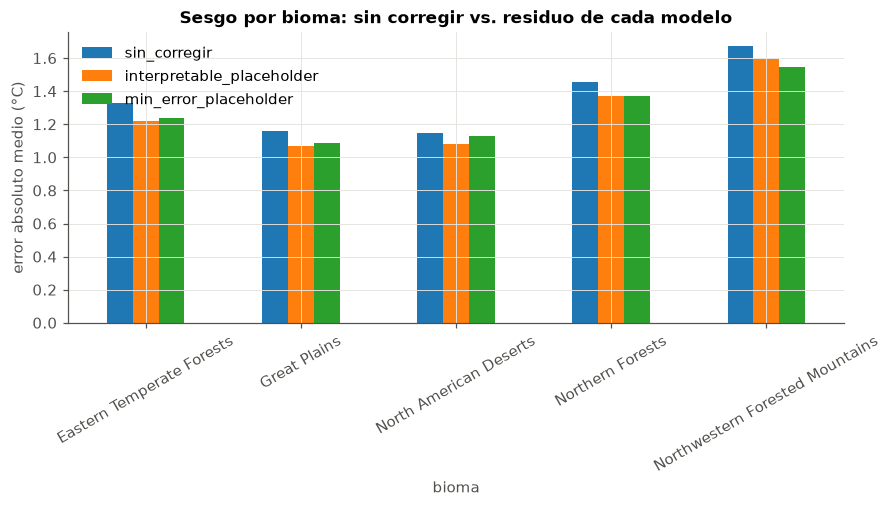

,sin_corregir,interpretable_placeholder,min_error_placeholder
bioma,,,
Eastern Temperate Forests,1.327,1.218,1.235
Great Plains,1.161,1.068,1.088
North American Deserts,1.147,1.078,1.129
Northern Forests,1.453,1.373,1.370
Northwestern Forested Mountains,1.672,1.593,1.548


In [12]:
sesgo_bioma = comparar_sesgo_por_corte(datos_test, 'bioma', predicciones_test, min_n=20)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
sesgo_bioma.plot(kind='bar', ax=ax)
ax.set(ylabel='error absoluto medio (°C)', title='Sesgo por bioma: sin corregir vs. residuo de cada modelo')
ax.tick_params(axis='x', rotation=30)
ax.legend(frameon=False)
figuras['04_sesgo_por_bioma_pre_post'] = fig
plt.show()
sesgo_bioma.round(3)

**Con los placeholders, no hay mucho para leer todavía** -son modelos sin tunear entrenados apurado para probar
el pipeline, no para corregir bien. Lo que importa de esta sección es que quedó funcionando el *chequeo* en sí: en
cuanto estén los modelos reales de Etapa A, esta misma celda va a decir si el sesgo por hora/bioma se achicó, se
mantuvo igual o -peor- se invirtió.

## 7. Qué reemplazar cuando esté lista la Etapa A

1. **Sección 3**: cambiar `modelo_interpretable_placeholder` y `modelo_min_error_placeholder` por los dos modelos
   reales (entrenados con validación cruzada, como pide la consigna). Si cualquiera de los dos no es lineal ni
   expone `feature_importances_`, revisar la sección 4 (puede necesitar otra técnica de importancia).
2. **Sección 5**: si el modelo de mínimo error no es un modelo de árbol/ensamble (p. ej. es una red neuronal o un
   SVR), cambiar `shap.TreeExplainer` por `shap.KernelExplainer` (más lento) o el explainer específico que
   corresponda.
3. **Secciones 6**: no requieren cambios más allá de que `predicciones_test` apunte a los modelos reales -los cortes
   (hora, bioma) y la función `comparar_sesgo_por_corte` quedan igual. Se puede sumar `elevation` (bucketizada) como
   tercer corte si hace falta, reusando la misma función.
4. **División train/test**: esta notebook usa la columna `split` de `dataset_modelado.csv` (mismo corte de fecha que
   `5_separacion_train_test.ipynb`). Si Etapa A usa otra estrategia de validación (p. ej. k-fold temporal), hay que
   alinear esta notebook a esa estrategia antes de comparar.

In [13]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')

resultados.to_csv(OUT + 'tabla_resultados_placeholder.csv', index=False)
importancia_interpretable.to_csv(OUT + 'tabla_feature_importance_interpretable.csv')
importancia_shap.to_csv(OUT + 'tabla_shap_min_error.csv')
sesgo_hora.to_csv(OUT + 'tabla_sesgo_por_hora.csv')
sesgo_bioma.to_csv(OUT + 'tabla_sesgo_por_bioma.csv')
print(f'Guardados {len(figuras)} gráfico(s) y 5 tablas en {OUT}')

Guardados 4 gráfico(s) y 5 tablas en ../data/out/interpretabilidad/
